In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.cluster import KMeans

In [5]:
import random
import numpy as np
import tensorflow as tf

In [7]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

HERE = Path(r"C:\Users\madhu\Desktop\CaliboPractice01")
OUT = HERE / 'outputs'
OUT.mkdir(exist_ok=True)

df = pd.read_csv(r"C:\Users\madhu\Desktop\CaliboPractice01\placement_proxy_synthetic.csv")

features = [c for c in df if c.startswith('feature_')]
X = df[features]
y = df['target']

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=.30, stratify=y, random_state=SEED
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=.50,
    stratify=y_temp, random_state=SEED
)

print(
    'SPLITS',
    len(X_train), len(X_val), len(X_test),
    'positive rates',
    *[round(v.mean(), 3) for v in (y_train, y_val, y_test)]
)

SPLITS 7000 1500 1500 positive rates 0.16 0.161 0.16


In [8]:
print("Input features:", X.shape[1])
print("Target:", y.name)
print("Target classes:", y.unique())

Input features: 30
Target: target
Target classes: [0 1]


In [9]:
print(X.isnull().sum()[X.isnull().sum() > 0])

feature_01    1123
dtype: int64


In [10]:
imputer = SimpleImputer(strategy='median', add_indicator=False)
scaler = StandardScaler()

train_imp = imputer.fit_transform(X_train)
val_imp = imputer.transform(X_val)
test_imp = imputer.transform(X_test)

Xtr = scaler.fit_transform(train_imp)
Xva = scaler.transform(val_imp)
Xte = scaler.transform(test_imp)

In [11]:
Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = ((X_train < lower) | (X_train > upper))

outlier_summary = pd.DataFrame({
    'Outlier_Count': outliers.sum(),
    'Outlier_Percentage': (outliers.mean() * 100).round(2)
})

outlier_summary = outlier_summary.sort_values(
    'Outlier_Count', ascending=False
)

display(outlier_summary)

,Outlier_Count,Outlier_Percentage
feature_22,179,2.56
feature_29,139,1.99
feature_05,118,1.69
feature_09,92,1.31
feature_10,89,1.27
feature_19,74,1.06
feature_20,65,0.93
feature_23,59,0.84
feature_14,57,0.81
feature_04,57,0.81


In [12]:
def make_model(n_inputs):
    m = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(n_inputs,)),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

    m.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return m

In [13]:
def metrics(truth, prob):
    pred = (prob >= .5).astype(int)

    return dict(
        accuracy=accuracy_score(truth, pred),
        precision=precision_score(truth, pred, zero_division=0),
        recall=recall_score(truth, pred, zero_division=0),
        f1=f1_score(truth, pred, zero_division=0),
        roc_auc=roc_auc_score(truth, prob)
    )

In [15]:
model = make_model(Xtr.shape[1])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
history = model.fit(
    Xtr, y_train,
    validation_data=(Xva, y_val),
    epochs=20,
    batch_size=32
)

Epoch 1/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8746 - loss: 0.3191 - val_accuracy: 0.9280 - val_loss: 0.2056
Epoch 2/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9313 - loss: 0.1958 - val_accuracy: 0.9420 - val_loss: 0.1706
Epoch 3/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9479 - loss: 0.1625 - val_accuracy: 0.9493 - val_loss: 0.1603
Epoch 4/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9561 - loss: 0.1432 - val_accuracy: 0.9500 - val_loss: 0.1550
Epoch 5/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9623 - loss: 0.1303 - val_accuracy: 0.9513 - val_loss: 0.1510
Epoch 6/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9660 - loss: 0.1211 - val_accuracy: 0.9493 - val_loss: 0.1487
Epoch 7/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9683 - loss: 0.1138 - val_accuracy: 0.9513 - val_loss: 0.1479
Epoch 8/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9714 - loss: 0.1080 - val_accuracy: 0.

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


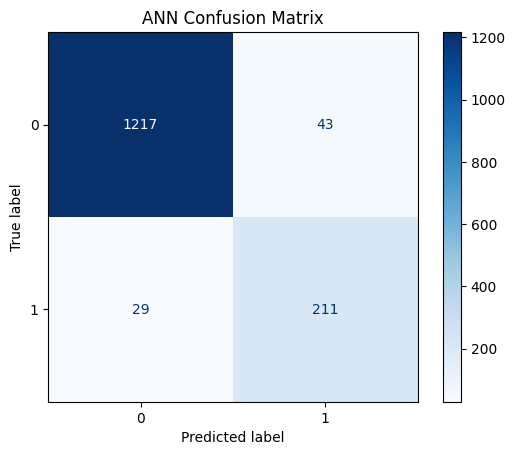

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_prob = model.predict(Xte).ravel()
y_pred = (y_prob >= 0.5).astype(int)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1]
)

disp.plot(cmap='Blues', values_format='d')
plt.title("ANN Confusion Matrix")
plt.show()

In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Predict probabilities
y_prob = model.predict(Xte).ravel()

# Convert probabilities to 0 or 1
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score :", f1_score(y_test, y_pred, zero_division=0))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))

# Detailed report for both classes
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Accuracy : 0.952
Precision: 0.8307086614173228
Recall   : 0.8791666666666667
F1 Score : 0.854251012145749
ROC-AUC  : 0.938614417989418

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.97      0.97      1260
           1       0.83      0.88      0.85       240

    accuracy                           0.95      1500
   macro avg       0.90      0.92      0.91      1500
weighted avg       0.95      0.95      0.95      1500



In [19]:
# Predict on validation data
val_prob = model.predict(Xva).ravel()
val_pred = (val_prob >= 0.5).astype(int)

# Create validation results
error_df = X_val.copy()
error_df['actual'] = y_val.to_numpy()
error_df['probability'] = val_prob
error_df['predicted'] = val_pred

# Keep only incorrect predictions
misclassified = error_df[
    error_df['actual'] != error_df['predicted']
].copy()

# Save CSV
misclassified.to_csv(
    OUT / 'misclassified_validation_rows.csv',
    index=False
)

print("Misclassified rows:", len(misclassified))
print("Saved to:", OUT / 'misclassified_validation_rows.csv')

display(misclassified.head(10))

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
Misclassified rows: 73
Saved to: C:\Users\madhu\Desktop\CaliboPractice01\outputs\misclassified_validation_rows.csv


,feature_00,feature_01,feature_02,feature_03,feature_04,feature_05,feature_06,feature_07,feature_08,feature_09,...,feature_23,feature_24,feature_25,feature_26,feature_27,feature_28,feature_29,actual,probability,predicted
6051,0.615371,0.177112,2.979678,-0.611677,0.718913,8.345201,3.819709,0.709494,0.593584,-11.921989,...,2.078764,-1.808155,-1.160141,2.879799,-1.587741,1.400420,-3.648418,0,0.645506,1
2257,0.353729,-0.925918,2.163285,-0.033684,0.412191,2.112625,3.834725,0.436807,1.693408,-2.931249,...,-0.460153,0.290747,-4.341989,0.791537,-0.625742,-1.142611,-2.946512,1,0.343201,0
2726,-2.073920,-1.395573,0.018820,1.456015,0.052433,2.166459,0.311127,-0.668415,-0.841190,2.151032,...,1.000108,1.198063,-1.502144,1.691281,1.272110,0.825866,0.914790,1,0.332150,0
8244,1.495712,-0.505350,-0.416888,-2.168029,0.588816,-3.547359,0.284460,-0.353814,-0.538643,4.753237,...,1.071888,1.173219,-1.875716,-3.243330,0.262253,-0.717920,-1.949453,1,0.119772,0
2304,0.228138,-0.900067,-0.475048,-1.115557,0.338197,-3.884256,-1.533130,-0.576513,1.754093,3.368778,...,-3.254540,-0.633939,-0.561539,1.013799,0.606557,0.355373,-1.398637,0,0.544523,1
7487,0.276179,NaN,-1.374819,-0.477765,2.015563,1.668103,1.368507,0.465004,-1.319203,-4.081938,...,-1.567467,-0.252252,3.531848,-1.721159,-0.852670,-1.074353,-2.501343,1,0.002786,0
9452,0.105149,-1.502977,-3.945454,-2.099268,1.145750,-6.008904,0.344193,0.878372,-1.035261,2.567085,...,3.905791,1.990967,-1.433777,-1.438873,0.294785,0.901888,-1.140096,1,0.000467,0
7265,-1.128335,NaN,-1.305495,-2.989753,-1.995090,-6.245818,1.134569,-0.459077,-0.708242,2.972271,...,0.266725,-1.080939,-5.363100,-1.958755,-1.080697,-0.393978,0.745847,0,0.893776,1
3815,-0.726488,-0.145656,-0.616895,3.816789,0.364206,5.476731,2.998034,-0.837022,1.402622,-7.231450,...,0.947047,2.966735,2.372270,1.604485,2.045162,0.493892,-0.793770,1,0.379192,0
5446,0.908943,-0.296117,-0.876687,2.180557,0.840440,-2.223144,-1.116117,1.435240,0.723941,-2.692738,...,-0.758436,-1.085042,0.417681,1.333675,-1.470866,-0.775173,-0.935363,1,0.002568,0


In [20]:
fp = ((misclassified['actual'] == 0) &
      (misclassified['predicted'] == 1)).sum()

fn = ((misclassified['actual'] == 1) &
      (misclassified['predicted'] == 0)).sum()

print("False Positives:", fp)
print("False Negatives:", fn)
print("Total mistakes:", len(misclassified))

False Positives: 39
False Negatives: 34
Total mistakes: 73


In [21]:
# Find incorrect predictions closest to 0.5
misclassified['distance_from_05'] = abs(
    misclassified['probability'] - 0.5
)

borderline_errors = misclassified.sort_values(
    'distance_from_05'
)

display(
    borderline_errors[
        ['actual', 'probability', 'predicted', 'distance_from_05']
    ].head(10)
)

,actual,probability,predicted,distance_from_05
2950,0,0.511229,1,0.011229
4116,0,0.518498,1,0.018498
3935,1,0.472768,0,0.027232
9962,1,0.471452,0,0.028548
2304,0,0.544523,1,0.044523
5326,0,0.556759,1,0.056759
8123,1,0.428228,0,0.071772
5598,0,0.574650,1,0.074650
2308,0,0.575612,1,0.075612
7856,0,0.579990,1,0.079990


In [22]:
# Confidence in the predicted class
misclassified['confidence'] = np.where(
    misclassified['predicted'] == 1,
    misclassified['probability'],
    1 - misclassified['probability']
)

# Sort mistakes by highest confidence
confident_errors = misclassified.sort_values(
    'confidence', ascending=False
)

display(
    confident_errors[
        ['actual', 'probability', 'predicted', 'confidence']
    ].head(10)
)

,actual,probability,predicted,confidence
6497,1,0.000047,0,0.999953
4969,1,0.000050,0,0.999950
8803,0,0.999788,1,0.999788
4152,1,0.000278,0,0.999722
659,1,0.000305,0,0.999695
9452,1,0.000467,0,0.999533
9271,1,0.000523,0,0.999477
9054,0,0.998966,1,0.998966
5446,1,0.002568,0,0.997432
3617,1,0.002634,0,0.997366


In [23]:
selected_rows = [2950, 6497, 8803]

columns = [
    'actual',
    'probability',
    'predicted',
    'confidence'
]

# Include all 30 original features
display(
    misclassified.loc[
        selected_rows,
        ['actual', 'probability', 'predicted'] + features
    ].T
)

,2950,6497,8803
actual,0.000000,1.000000,0.000000
probability,0.511229,0.000047,0.999788
predicted,1.000000,0.000000,1.000000
feature_00,0.122227,-0.041652,-0.667349
feature_01,-0.089399,0.475545,0.023214
feature_02,-2.565900,-1.202930,-3.286819
feature_03,1.030832,4.295680,4.776042
feature_04,-0.523556,0.531123,-0.682173
feature_05,0.099848,-7.318939,8.395475
feature_06,0.717290,-1.299975,4.148963


In [24]:
selected_rows = [2950, 6497, 8803]

selected_features = X_val.loc[selected_rows]

outlier_flags = (
    selected_features.lt(lower) |
    selected_features.gt(upper)
)

for row_id in selected_rows:
    flagged = outlier_flags.columns[outlier_flags.loc[row_id]]

    print(f"\nRow {row_id}")
    print("Outlier count:", len(flagged))
    print("Outlier features:", list(flagged))


Row 2950
Outlier count: 0
Outlier features: []

Row 6497
Outlier count: 0
Outlier features: []

Row 8803
Outlier count: 3
Outlier features: ['feature_16', 'feature_22', 'feature_29']


In [25]:
# Check missing values in incorrectly classified rows
missing_errors = X_val.loc[misclassified.index].isnull().sum()

print("Missing values among incorrect predictions:")
print(missing_errors[missing_errors > 0])

print("\nMissing values in selected rows:")
print(X_val.loc[[2950, 6497, 8803]].isnull().sum(axis=1))

Missing values among incorrect predictions:
feature_01    4
dtype: int64

Missing values in selected rows:
2950    0
6497    0
8803    0
dtype: int64


In [26]:
validation_check = X_val.copy()

validation_check['is_error'] = (
    val_pred != y_val.to_numpy()
)

validation_check['feature_01_missing'] = (
    X_val['feature_01'].isna()
)

print(
    validation_check.groupby('feature_01_missing')['is_error']
    .agg(['count', 'sum', 'mean'])
)

                    count  sum      mean
feature_01_missing                      
False                1345   69  0.051301
True                  155    4  0.025806
